# 04 多城市检索结果可视化诊断

本 notebook **不重新计算指标或检索**，只读取 `05_global_query_selection_and_retrieval.ipynb` 已保存的全局分层查询结果。目标是直观看清三件事：

1. 19 个城市的样本量与屋顶指标分布是否存在明显差异；
2. 加入屋顶信息后，各查询的屋顶相似性改善了多少，同时损失了多少总体形态可比性；
3. 对代表性查询，M1 与 M2 的前 5 个候选在平面和 LOD2 轴测图上究竟发生了什么变化。

本流程只从数据库读取少量几何，不新建 schema 或 table。

In [11]:
from __future__ import annotations

import importlib
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

def find_notebook_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'multicity_visualization.py').is_file():
        return current
    for parent in (current, *current.parents):
        candidate = parent / 'casebase' / 'lod2_roof_retrieval_experiment'
        if (candidate / 'multicity_visualization.py').is_file():
            return candidate
    raise FileNotFoundError('未找到 lod2_roof_retrieval_experiment 目录。')

NOTEBOOK_DIR = find_notebook_dir()
os.chdir(NOTEBOOK_DIR)
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import multicity_database as mdb
import multicity_visualization as mviz

for module in (mdb, mviz):
    importlib.reload(module)

## 1. 可视化设置

默认从五种屋顶类别中各选 1 个接近该类总体表现的查询，而不是挑选增益最大的极端案例。设置 `RENDER_ALL_QUERIES=True` 可以输出全部正式查询；也可以在 `QUERY_IDS_TO_RENDER` 中手动指定。平面图较快，LOD2 轴测图会更慢。

In [12]:
TOP_K = 5
QUERY_IDS_TO_RENDER = None  # 例如 ['DE_BE_000001']；None 表示自动选代表案例
EXAMPLES_PER_CATEGORY = 1
RENDER_ALL_QUERIES = False
GENERATE_PLAN = True
GENERATE_AXONOMETRIC = True
ENV_PATH = None  # 找不到项目 .env 时，在这里填写路径

MULTICITY_DIR = NOTEBOOK_DIR / 'outputs' / 'multicity'
RESULT_DIR = MULTICITY_DIR / 'global_queries'
FIGURE_DIR = RESULT_DIR / 'figures'
CASE_DIR = FIGURE_DIR / 'cases'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CASE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR

WindowsPath('E:/0_code/block-gml-casebase/casebase/lod2_roof_retrieval_experiment/outputs/multicity/global_queries/figures')

## 2. 读取 03 已保存的结果

若这里报文件不存在，请先完整运行05。城市样本统计仍读取03的输出，查询和检索结果读取05的 `outputs/multicity/global_queries/`。

In [13]:
required_files = {
    'retrieval': RESULT_DIR / 'global_retrieval_results.csv',
    'city_summary': MULTICITY_DIR / 'city_summary.csv',
    'city_features': MULTICITY_DIR / 'city_feature_medians.csv',
    'queries': RESULT_DIR / 'global_formal_queries.csv',
}
missing_files = [str(path) for path in required_files.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError('缺少03或05的完整输出：\n' + '\n'.join(missing_files))

retrieval = pd.read_csv(required_files['retrieval'], encoding='utf-8-sig')
city_summary = pd.read_csv(required_files['city_summary'], encoding='utf-8-sig')
city_feature_medians = pd.read_csv(required_files['city_features'], encoding='utf-8-sig')
formal_queries = pd.read_csv(required_files['queries'], encoding='utf-8-sig')

expected_rows = len(formal_queries) * 2 * TOP_K
if len(retrieval) != expected_rows:
    raise ValueError(f'检索结果有 {len(retrieval)} 行，按查询数应为 {expected_rows} 行。')

pd.Series({
    'cities': int(city_summary['city'].nunique()),
    'selected_blocks': int(city_summary['selected_blocks'].sum()),
    'formal_queries': int(len(formal_queries)),
    'retrieval_rows': int(len(retrieval)),
})

cities                19
selected_blocks    47323
formal_queries        50
retrieval_rows       500
dtype: int64

## 3. 总览图：城市样本与屋顶特征

这张图不是为了证明哪个城市更“好”，而是检查不同城市的屋顶指标是否处在明显不同的分布区间。特别极端的城市可能同时反映真实形态差异与数据建模方式差异，后续解释时需要谨慎。

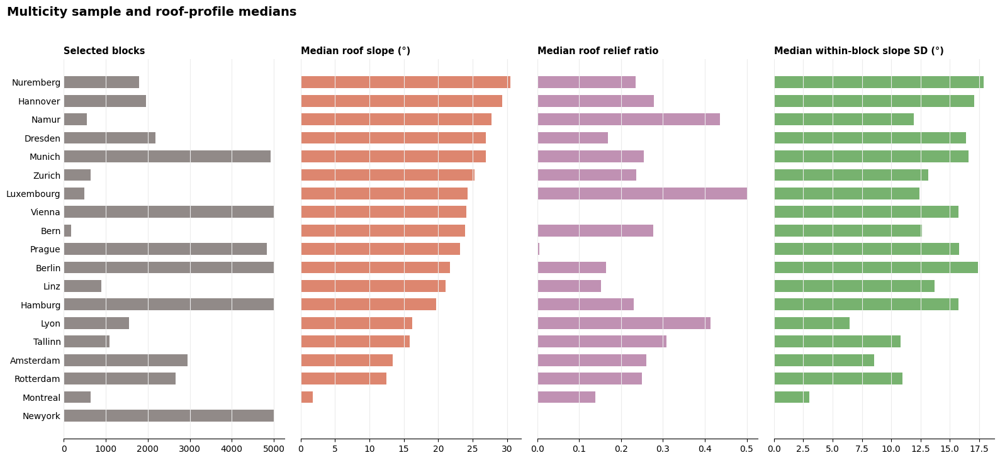

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\city_sample_and_roof_profiles.png


In [14]:
city_profile_path = FIGURE_DIR / 'city_sample_and_roof_profiles.png'
fig = mviz.make_city_roof_profile_figure(
    city_summary, city_feature_medians, city_profile_path
)
plt.show()
print(city_profile_path)

## 4. 总览图：屋顶增益与总体形态代价

横轴是 M2 相比 M1 增加的总体形态距离，越向右表示为匹配屋顶付出的总体可比性代价越大；纵轴是屋顶距离的减少量，越向上表示屋顶匹配改善越明显。圆越大，M1 与 M2 的前 5 名候选替换得越多。

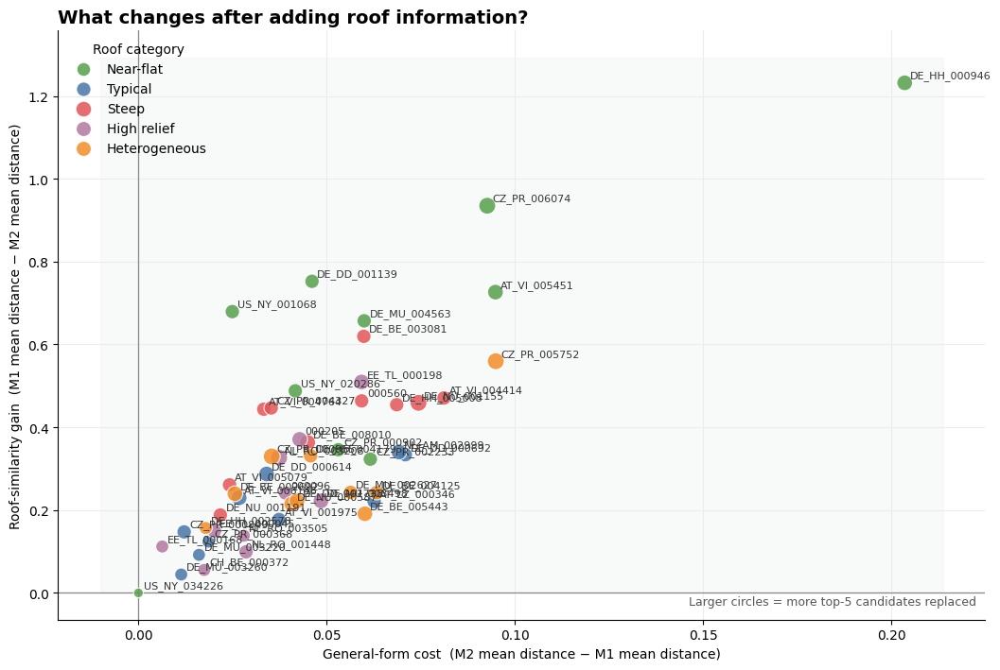

,query_id,roof_gain,general_cost,top_k_overlap,replacement_count,m1_general_mean,m2_general_mean,m1_roof_mean,m2_roof_mean,query_category,query_category_label,query_selection_rank,query_target_distance
7,DE_HH_000946,1.232,0.203,1,4,0.566,0.770,1.256,0.025,near_flat,Near-flat,8,0.0295423464084923
1,CZ_PR_006074,0.935,0.093,0,5,0.476,0.569,0.941,0.006,near_flat,Near-flat,2,0.0295423464084923
4,DE_DD_001139,0.752,0.046,2,3,0.386,0.432,0.775,0.023,near_flat,Near-flat,5,0.0295423464084923
9,AT_VI_005451,0.726,0.095,1,4,0.295,0.390,0.862,0.136,near_flat,Near-flat,10,0.0295423464084923
6,US_NY_001068,0.679,0.025,2,3,0.296,0.321,0.679,0.000,near_flat,Near-flat,7,0.0295423464084923
8,DE_MU_004563,0.657,0.060,2,3,0.321,0.381,0.883,0.226,near_flat,Near-flat,9,0.0295423464084923
29,DE_BE_003081,0.620,0.060,2,3,0.381,0.441,0.791,0.172,steep,Steep,10,0.0411373301680975
49,CZ_PR_005752,0.559,0.095,0,5,0.359,0.454,0.879,0.319,heterogeneous,Heterogeneous,10,0.0330114087847631
33,EE_TL_000198,0.509,0.059,1,4,0.245,0.304,0.800,0.291,high_relief,High relief,4,0.0148143850916621
5,US_NY_020286,0.488,0.042,2,3,0.337,0.379,0.488,0.000,near_flat,Near-flat,6,0.0295423464084923


In [15]:
query_diagnostics = mviz.build_query_gain_cost(retrieval, top_k=TOP_K)
gain_cost_path = FIGURE_DIR / 'query_gain_cost.png'
fig = mviz.make_query_gain_cost_figure(query_diagnostics, gain_cost_path)
plt.show()

display(
    query_diagnostics.sort_values(['roof_gain', 'general_cost'], ascending=[False, True])
    .style.format({
        'roof_gain': '{:.3f}', 'general_cost': '{:.3f}',
        'm1_general_mean': '{:.3f}', 'm2_general_mean': '{:.3f}',
        'm1_roof_mean': '{:.3f}', 'm2_roof_mean': '{:.3f}',
    })
)

## 5. 总览图：候选城市构成变化

这张图统计各城市在全部查询的前 5 名中出现多少次。它能揭示屋顶指标是否把检索结果集中推向少数城市，也能暴露潜在的数据源建模偏差。

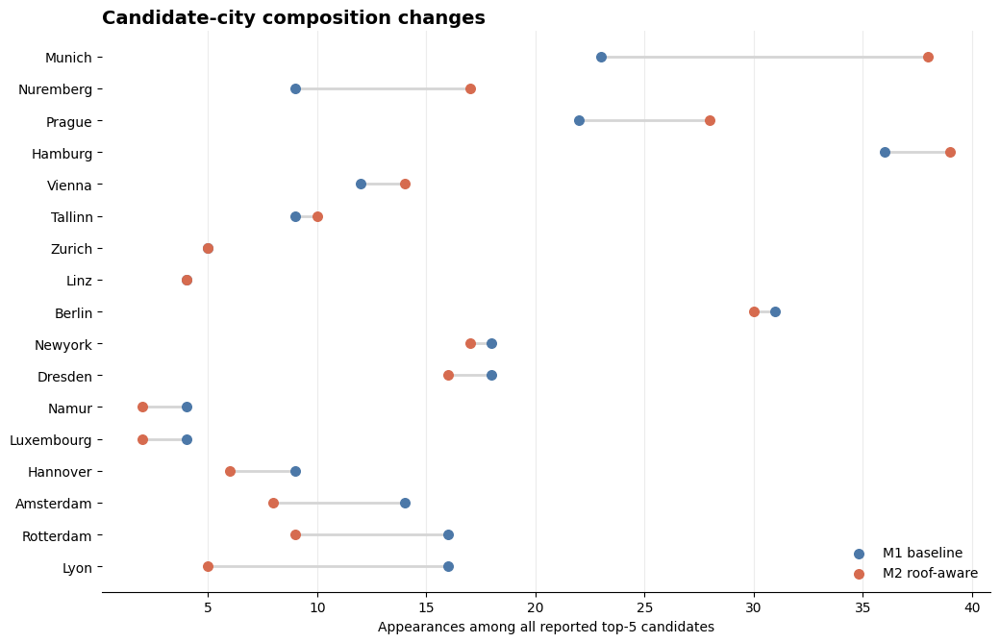

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\candidate_city_shift.png


In [16]:
city_shift_path = FIGURE_DIR / 'candidate_city_shift.png'
fig = mviz.make_candidate_city_shift_figure(retrieval, city_shift_path)
plt.show()
print(city_shift_path)

## 6. 确定要绘制的查询

下面先列出自动选择的类别代表案例。代表性按照各类别在屋顶增益、总体形态代价和候选替换数量上的中位表现确定。它们用于直观检查，不参与正式查询集的选择。

In [17]:
available_query_ids = sorted(retrieval['query_id'].astype(str).unique())
if QUERY_IDS_TO_RENDER is not None:
    query_ids = [str(query_id) for query_id in QUERY_IDS_TO_RENDER]
    visual_examples = query_diagnostics[query_diagnostics['query_id'].isin(query_ids)].copy()
elif RENDER_ALL_QUERIES:
    query_ids = available_query_ids
    visual_examples = query_diagnostics.copy()
else:
    visual_examples = mviz.select_category_examples(
        query_diagnostics, per_category=EXAMPLES_PER_CATEGORY
    )
    query_ids = visual_examples['query_id'].astype(str).tolist()
unknown_query_ids = sorted(set(query_ids) - set(available_query_ids))
if unknown_query_ids:
    raise ValueError('检索结果中没有这些 query：' + ', '.join(unknown_query_ids))

display(
    visual_examples
    .sort_values(['query_category', 'query_id'])
    .reset_index(drop=True)
)
print(f'将绘制 {len(query_ids)} 个查询。')

,query_id,roof_gain,general_cost,top_k_overlap,replacement_count,m1_general_mean,m2_general_mean,m1_roof_mean,m2_roof_mean,query_category,query_category_label,query_selection_rank,query_target_distance,example_distance,example_role
0,DE_DD_001738,0.222041,0.042107,1,4,0.378592,0.420699,0.371876,0.149835,heterogeneous,Heterogeneous,9,0.0282437259440634,0.126865,category_representative
1,NL_RO_001448,0.099116,0.028590,2,3,0.181238,0.209828,0.344522,0.245407,high_relief,High relief,10,0.025626425619911,0.298326,category_representative
2,DE_MU_004563,0.657037,0.059947,2,3,0.320573,0.380519,0.882589,0.225553,near_flat,Near-flat,9,0.0295423464084923,0.050275,category_representative
3,LU_LU_000560,0.463648,0.059270,2,3,0.399941,0.459211,0.732439,0.268791,steep,Steep,7,0.0268394163280742,0.158804,category_representative
4,AT_VI_001975,0.177236,0.037329,2,3,0.289814,0.327143,0.408939,0.231703,typical,Typical,5,0.0107724332656008,0.134286,category_representative


将绘制 5 个查询。


## 7. 从数据库读取少量几何

只读取上述查询及其 M1/M2 候选的街区边界、建筑轮廓和 LOD2 surface。城市名与街区 ID 始终成对使用，避免跨城市 ID 重名。此步骤没有数据库写入。

In [18]:
scene_keys = mviz.scene_keys_for_queries(query_ids, retrieval, top_k=TOP_K)
needed_cities = sorted({city for city, _ in scene_keys})

connection = mdb.connect_from_env(ENV_PATH)
catalog_sources = {source.city: source for source in mdb.discover_lod2_cities(connection)}
missing_cities = sorted(set(needed_cities) - set(catalog_sources))
if missing_cities:
    connection.close()
    raise ValueError('数据库目录中缺少城市：' + ', '.join(missing_cities))
for city in needed_cities:
    mdb.validate_source_columns(connection, catalog_sources[city])

scenes = mviz.fetch_multicity_scenes(
    connection, catalog_sources, scene_keys
)
missing_scenes = sorted(set(scene_keys) - set(scenes))
if missing_scenes:
    connection.close()
    raise ValueError('这些街区没有读到几何：' + ', '.join(f'{c}/{b}' for c, b in missing_scenes))

print(f'从 {len(needed_cities)} 个城市读取 {len(scenes)} 个唯一街区场景。')

从 12 个城市读取 46 个唯一街区场景。


## 8. 输出 M1/M2 平面对照图

所有子图独立缩放到画框，以便比较街区内部构成；面积、建筑数和 BCR 写在图内，避免把独立缩放误读为真实尺度相同。

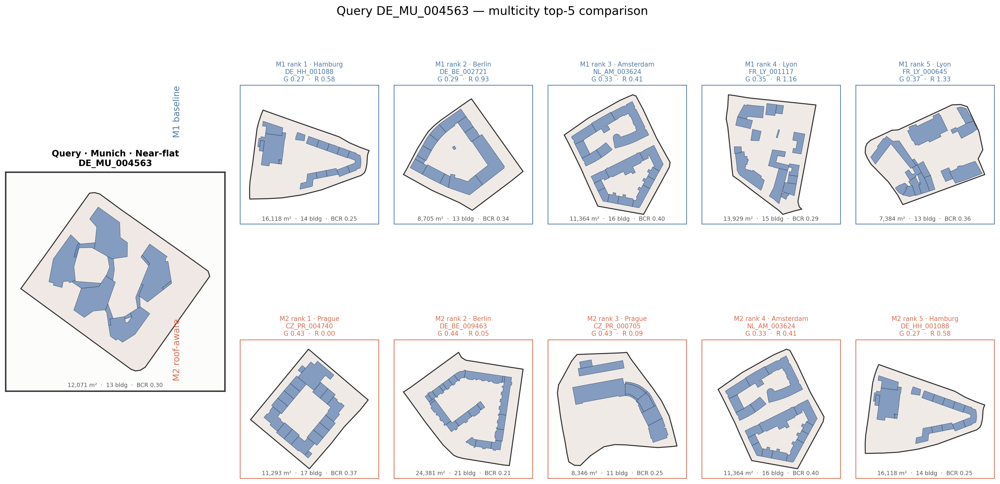

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\DE_MU_004563_plan.png


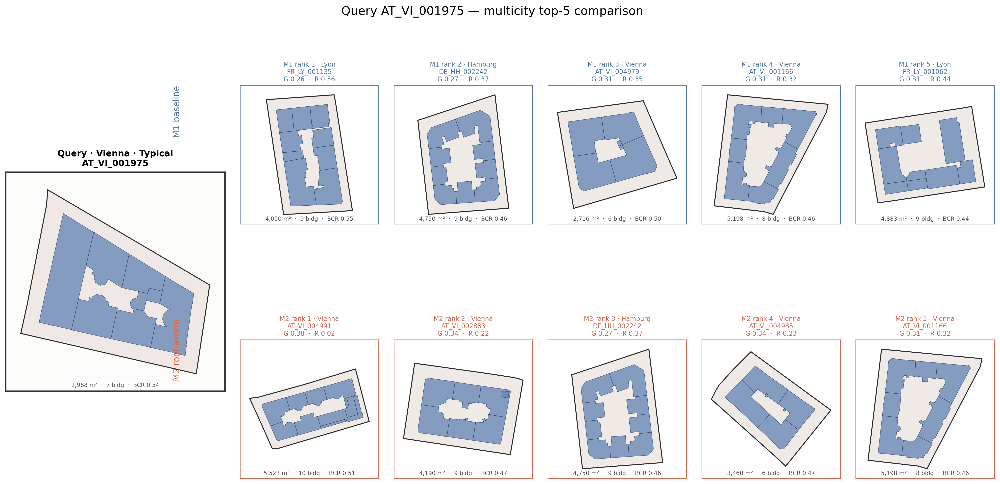

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\AT_VI_001975_plan.png


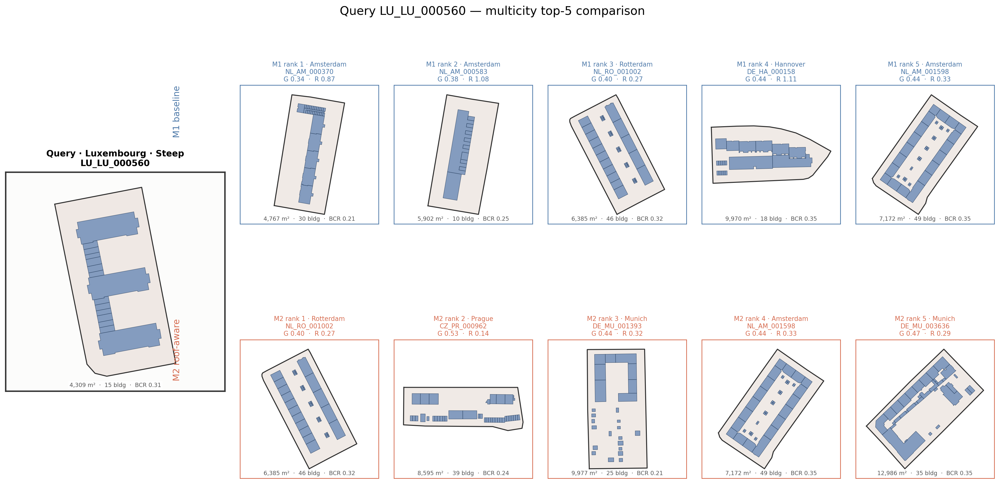

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\LU_LU_000560_plan.png


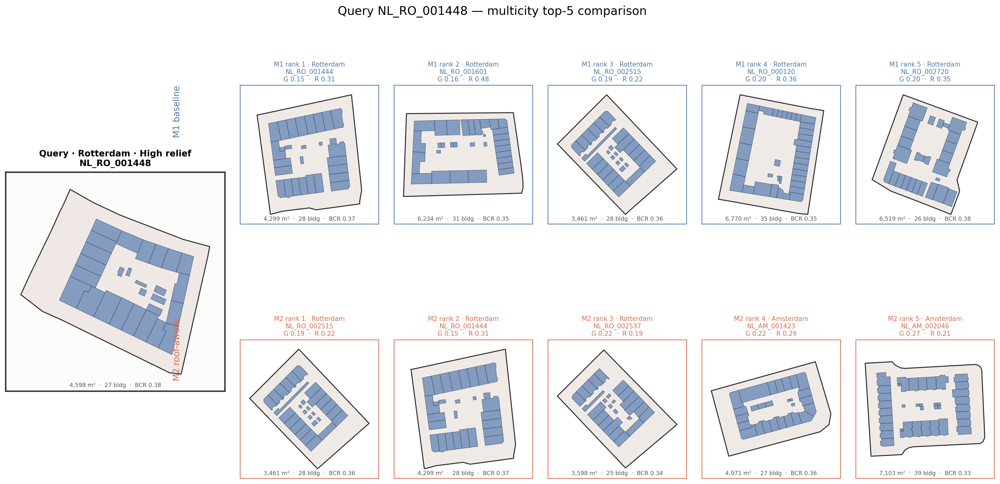

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\NL_RO_001448_plan.png


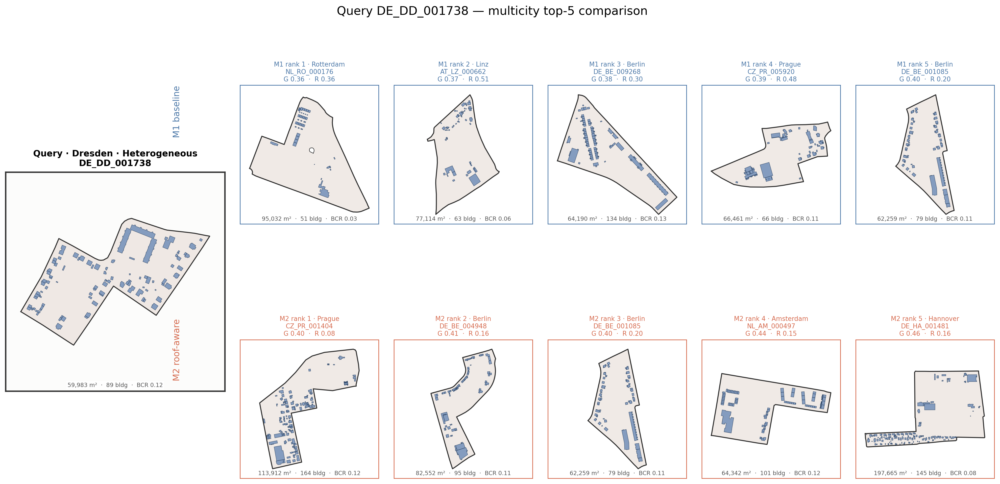

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\DE_DD_001738_plan.png


In [19]:
figure_rows = []
if GENERATE_PLAN:
    for query_id in query_ids:
        path = CASE_DIR / f'{query_id}_plan.png'
        mviz.save_multicity_plan_comparison(
            query_id, retrieval, scenes, path, top_k=TOP_K
        )
        figure_rows.append({'query_id': query_id, 'view': 'plan', 'path': str(path)})
        display(Image(filename=str(path)))
        print(path)

## 9. 输出 M1/M2 LOD2 轴测对照图

这一节会逐个场景离屏渲染，速度明显慢于平面图。所有候选都用原始 LOD2 几何展示，因此可以直接观察 M2 是否真的找到了更接近查询的屋顶起伏与坡度组合。

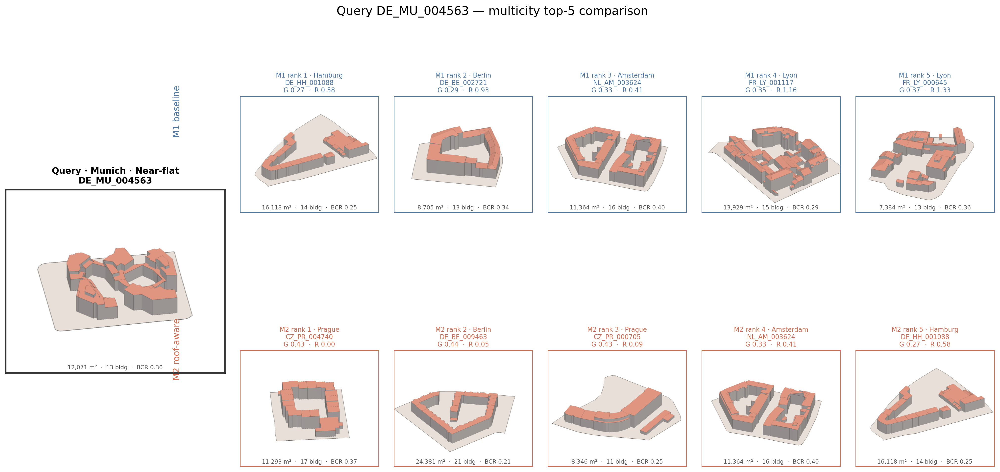

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\DE_MU_004563_axonometric.png


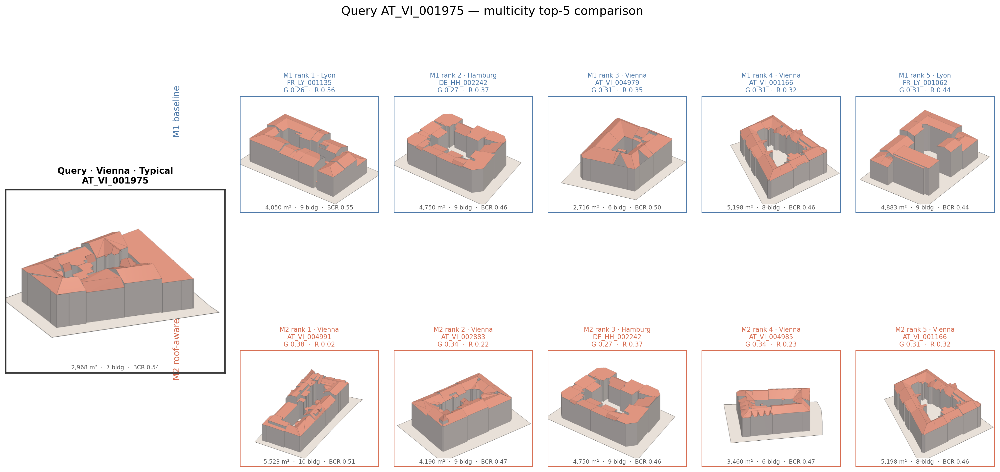

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\AT_VI_001975_axonometric.png


E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\LU_LU_000560_axonometric.png


E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\NL_RO_001448_axonometric.png


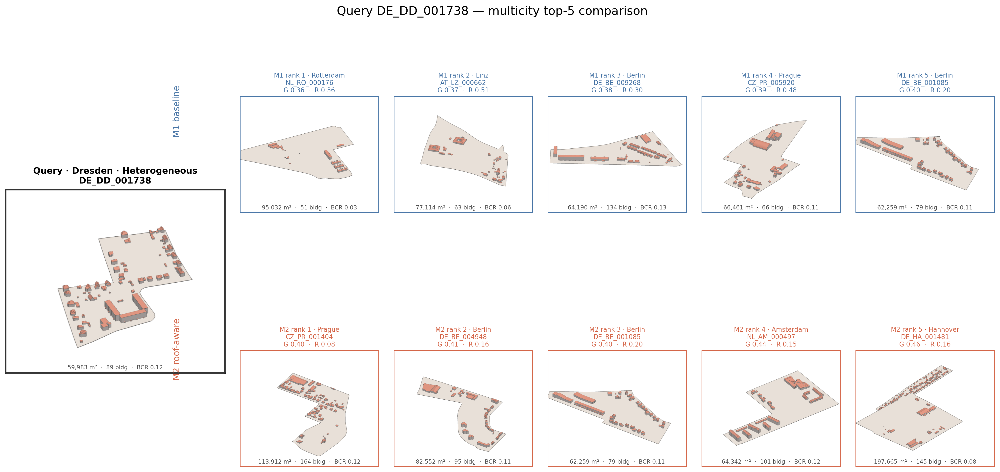

E:\0_code\block-gml-casebase\casebase\lod2_roof_retrieval_experiment\outputs\multicity\global_queries\figures\cases\DE_DD_001738_axonometric.png


In [20]:
if GENERATE_AXONOMETRIC:
    for query_id in query_ids:
        path = CASE_DIR / f'{query_id}_axonometric.png'
        mviz.save_multicity_axonometric_comparison(
            query_id, retrieval, scenes, path, top_k=TOP_K
        )
        figure_rows.append({'query_id': query_id, 'view': 'axonometric', 'path': str(path)})
        display(Image(filename=str(path)))
        print(path)

## 10. 保存索引并关闭连接

先比较五类代表案例是否符合直觉，再决定是否提高 `EXAMPLES_PER_CATEGORY` 或启用 `RENDER_ALL_QUERIES`。重点观察：M2 的屋顶是否更接近、总体布局是否仍可比较，以及不同类别是否呈现不同的增益和代价。

In [ ]:
figure_index = pd.DataFrame(figure_rows)
figure_index_path = FIGURE_DIR / 'case_figure_index.csv'
figure_index.to_csv(figure_index_path, index=False, encoding='utf-8-sig')
connection.close()
display(figure_index)
print(f'全部图片保存在：{FIGURE_DIR}')

## 11. 一次性输出全部50个查询的排序轴测图

下面的代码单元可以独立运行，不依赖前面单元保留的变量。它不会在 notebook 中显示图片，而是把全部50张轴测对照图分批写入磁盘。编号综合考虑两项同等权重的浏览指标：屋顶距离改善越大越好、总体形态距离增加越小越好。该编号只帮助人工浏览，不替代分类汇总或正式评价。

In [21]:
# 本单元可独立运行；只输出文件和简短进度，不嵌入图片。
from pathlib import Path
import importlib
import os
import sys
import pandas as pd

def locate_experiment_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'multicity_visualization.py').is_file():
        return current
    for parent in (current, *current.parents):
        candidate = parent / 'casebase' / 'lod2_roof_retrieval_experiment'
        if (candidate / 'multicity_visualization.py').is_file():
            return candidate
    raise FileNotFoundError('未找到 lod2_roof_retrieval_experiment 目录。')

batch_notebook_dir = locate_experiment_dir()
os.chdir(batch_notebook_dir)
if str(batch_notebook_dir) not in sys.path:
    sys.path.insert(0, str(batch_notebook_dir))

import multicity_database as batch_mdb
import multicity_visualization as batch_mviz
importlib.reload(batch_mviz)

BATCH_TOP_K = 5
BATCH_QUERY_COUNT = 5
BATCH_ENV_PATH = None
batch_result_dir = batch_notebook_dir / 'outputs' / 'multicity' / 'global_queries'
batch_retrieval_path = batch_result_dir / 'global_retrieval_results.csv'
batch_output_dir = batch_result_dir / 'figures' / 'all_queries_ranked_axonometric'
batch_output_dir.mkdir(parents=True, exist_ok=True)

batch_retrieval = pd.read_csv(batch_retrieval_path, encoding='utf-8-sig')
batch_diagnostics = batch_mviz.build_query_gain_cost(
    batch_retrieval, top_k=BATCH_TOP_K
)
ranked_queries = batch_mviz.rank_query_effects(batch_diagnostics)
query_cities = (
    batch_retrieval[['query_id', 'query_city']]
    .drop_duplicates('query_id').set_index('query_id')['query_city']
)
ranked_queries['query_city'] = ranked_queries['query_id'].map(query_cities)

all_query_ids = ranked_queries['query_id'].astype(str).tolist()
all_scene_keys = batch_mviz.scene_keys_for_queries(
    all_query_ids, batch_retrieval, top_k=BATCH_TOP_K
)
all_needed_cities = sorted({city for city, _ in all_scene_keys})
batch_connection = batch_mdb.connect_from_env(BATCH_ENV_PATH)
written_rows = []
try:
    batch_sources = {
        source.city: source
        for source in batch_mdb.discover_lod2_cities(batch_connection)
    }
    missing_cities = sorted(set(all_needed_cities) - set(batch_sources))
    if missing_cities:
        raise ValueError('数据库目录中缺少城市：' + ', '.join(missing_cities))
    for city in all_needed_cities:
        batch_mdb.validate_source_columns(batch_connection, batch_sources[city])

    for batch_start in range(0, len(ranked_queries), BATCH_QUERY_COUNT):
        query_batch = ranked_queries.iloc[
            batch_start:batch_start + BATCH_QUERY_COUNT
        ]
        batch_ids = query_batch['query_id'].astype(str).tolist()
        batch_scene_keys = batch_mviz.scene_keys_for_queries(
            batch_ids, batch_retrieval, top_k=BATCH_TOP_K
        )
        batch_scenes = batch_mviz.fetch_multicity_scenes(
            batch_connection, batch_sources, batch_scene_keys
        )
        missing_scenes = sorted(set(batch_scene_keys) - set(batch_scenes))
        if missing_scenes:
            raise ValueError(
                '这些街区没有读到几何：'
                + ', '.join(f'{city}/{block_id}' for city, block_id in missing_scenes)
            )

        for query in query_batch.itertuples(index=False):
            category = str(query.query_category)
            filename = (
                f'{int(query.effect_rank):02d}_{category}_'
                f'{query.query_id}_axonometric.png'
            )
            output_path = batch_output_dir / filename
            batch_mviz.save_multicity_axonometric_comparison(
                str(query.query_id), batch_retrieval, batch_scenes,
                output_path, top_k=BATCH_TOP_K,
            )
            written_rows.append({
                'effect_rank': int(query.effect_rank),
                'query_id': str(query.query_id),
                'query_city': str(query.query_city),
                'query_category': category,
                'roof_gain': float(query.roof_gain),
                'general_cost': float(query.general_cost),
                'effect_balance_score': float(query.effect_balance_score),
                'top_k_overlap': int(query.top_k_overlap),
                'path': str(output_path),
            })
            print(
                f'[{int(query.effect_rank):02d}/{len(ranked_queries):02d}] '
                f'{query.query_id} -> {filename}'
            )
        del batch_scenes
finally:
    batch_connection.close()

ranked_axonometric_index = pd.DataFrame(written_rows).sort_values('effect_rank')
ranked_index_path = batch_output_dir / 'ranked_axonometric_index.csv'
ranked_axonometric_index.to_csv(ranked_index_path, index=False, encoding='utf-8-sig')
print(f'完成：{len(ranked_axonometric_index)} 张图片')
print(f'目录：{batch_output_dir}')
print(f'排序索引：{ranked_index_path}')

[01/50] US_NY_001068 -> 01_near_flat_US_NY_001068_axonometric.png
[02/50] DE_DD_001139 -> 02_near_flat_DE_DD_001139_axonometric.png
[03/50] AT_VI_004764 -> 03_steep_AT_VI_004764_axonometric.png
[04/50] CZ_PR_004327 -> 04_steep_CZ_PR_004327_axonometric.png
[05/50] US_NY_020286 -> 05_near_flat_US_NY_020286_axonometric.png
[06/50] AT_VI_005079 -> 06_steep_AT_VI_005079_axonometric.png
[07/50] DE_MU_004563 -> 07_near_flat_DE_MU_004563_axonometric.png
[08/50] DE_BE_003081 -> 08_steep_DE_BE_003081_axonometric.png
[09/50] EE_TL_000198 -> 09_high_relief_EE_TL_000198_axonometric.png
[10/50] CZ_PR_000955 -> 10_heterogeneous_CZ_PR_000955_axonometric.png
[11/50] LU_LU_000205 -> 11_high_relief_LU_LU_000205_axonometric.png
[12/50] DE_DD_000614 -> 12_typical_DE_DD_000614_axonometric.png
[13/50] DE_BE_002692 -> 13_heterogeneous_DE_BE_002692_axonometric.png
[14/50] AT_VI_006146 -> 14_typical_AT_VI_006146_axonometric.png
[15/50] CZ_PR_000849 -> 15_typical_CZ_PR_000849_axonometric.png
[16/50] DE_BE_008010